# Floor 6 Zone 1/2/4/5 Statistical Baseline Methods and Comparison

本 notebook 是 baseline analysis 的最终优化版，用于展示三个 statistical baseline 方法及其结果对比。

与之前的合并版不同，本版本不再重复复制 v1、v2a、v2b 的完整代码，而是先定义通用数据处理函数和异常检测函数，再用三个不同的方法配置运行 baseline。这样结构更清楚，也更适合作为给老师查看的最终版本。

本 notebook 包含：

- Common setup and shared functions
- Baseline v1: hourly contextual statistical baseline
- Baseline v2a: 15-minute slot statistical baseline
- Baseline v2b: operation-aware threshold baseline
- Comparison of anomaly points, anomaly events, variables, zones, operating periods and overlap


## 1. Common Setup

这一部分导入依赖库，定义输入数据、输出目录、变量列表、运行时段和三个 baseline 方法的配置。所有方法共用同一份 baseline-ready dataset。


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 160)
pd.set_option("display.width", 220)
plt.style.use("default")
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False


def safe_print(*args) -> None:
    text = " ".join(str(arg) for arg in args)
    try:
        print(text)
    except UnicodeEncodeError:
        print(text.encode("ascii", errors="backslashreplace").decode("ascii"))


NOTEBOOK_CWD = Path.cwd()
INPUT_DATASET = (
    NOTEBOOK_CWD
    / "outputs"
    / "floor6_zone1245_2018_jul01_sep01_total_ac_eda"
    / "floor6_zone1245_baseline_ready_2018_jul01_sep01.csv.gz"
)

OPTIMIZED_OUTPUT_DIR = NOTEBOOK_CWD / "outputs" / "floor6_zone1245_baseline_methods_optimized"
OPTIMIZED_TABLE_DIR = OPTIMIZED_OUTPUT_DIR / "tables"
OPTIMIZED_FIGURE_DIR = OPTIMIZED_OUTPUT_DIR / "figures"
OPTIMIZED_TABLE_DIR.mkdir(parents=True, exist_ok=True)
OPTIMIZED_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

ROLLING_VARIABLE_COLUMNS = [
    "total_AC_power_kw_rolling_mean_15min",
    "light_power_kw_rolling_mean_15min",
    "plug_power_kw_rolling_mean_15min",
    "temperature_c_rolling_mean_15min",
    "humidity_pct_rolling_mean_15min",
    "lux_rolling_mean_15min",
]

VARIABLE_LABELS = {
    "total_AC_power_kw_rolling_mean_15min": "total_AC_power_kw",
    "light_power_kw_rolling_mean_15min": "light_power_kw",
    "plug_power_kw_rolling_mean_15min": "plug_power_kw",
    "temperature_c_rolling_mean_15min": "temperature_c",
    "humidity_pct_rolling_mean_15min": "humidity_pct",
    "lux_rolling_mean_15min": "lux",
}

WAS_MISSING_COLUMNS = {
    "total_AC_power_kw": "total_AC_power_kw_was_missing",
    "light_power_kw": "light_power_kw_was_missing",
    "plug_power_kw": "plug_power_kw_was_missing",
    "temperature_c": "temperature_c_was_missing",
    "humidity_pct": "humidity_pct_was_missing",
    "lux": "lux_was_missing",
}

MAD_EPSILON = 1e-9
DEFAULT_ROBUST_Z_THRESHOLD = 3.5
DEFAULT_MIN_PERSISTENCE_MINUTES = 15

ZERO_AWARE_VARIABLES = {"total_AC_power_kw", "light_power_kw", "lux"}
ENERGY_LIKE_VARIABLES = {"total_AC_power_kw", "light_power_kw", "plug_power_kw", "lux"}
ENVIRONMENT_VARIABLES = {"temperature_c", "humidity_pct"}
NON_WORK_PERIODS = {"evening_off", "night_off", "weekend"}
WORK_PERIODS = {"core_work", "ramp_up", "ramp_down"}

SMALL_MIN_THRESHOLDS = {
    "total_AC_power_kw": 1.0,
    "light_power_kw": 0.2,
    "plug_power_kw": 0.2,
    "lux": 5.0,
}

OPERATING_PERIOD_ORDER = ["core_work", "ramp_up", "ramp_down", "evening_off", "night_off", "weekend"]

PERIOD_ROBUST_Z_THRESHOLDS = {
    "core_work": 4.0,
    "ramp_up": 4.0,
    "ramp_down": 4.0,
    "evening_off": 3.5,
    "night_off": 3.0,
    "weekend": 3.0,
}

METHOD_CONFIGS = {
    "v1_hourly": {
        "label": "v1 hourly",
        "baseline_group_columns": ["zone", "day_type", "hour", "variable"],
        "rule_type": "standard",
        "description": "Hourly contextual baseline using robust z-score and zero-aware rule.",
    },
    "v2a_15min_slot": {
        "label": "v2a 15min slot",
        "baseline_group_columns": ["zone", "day_type", "fifteen_minute_slot", "variable"],
        "rule_type": "standard",
        "description": "Finer 15-minute slot baseline to test intra-hour sensitivity.",
    },
    "v2b_operation_aware": {
        "label": "v2b operation-aware",
        "baseline_group_columns": ["zone", "day_type", "hour", "variable"],
        "rule_type": "operation_aware",
        "description": "Hourly baseline with period-aware thresholds, variable-specific rules, dynamic persistence and severity ranking.",
    },
}

safe_print("Input dataset:", INPUT_DATASET)
safe_print("Optimized output:", OPTIMIZED_OUTPUT_DIR)


Input dataset: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\floor6_zone1245_baseline_ready_2018_jul01_sep01.csv.gz
Optimized output: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_baseline_methods_optimized


### 本步骤结果解释

这里把所有方法都会用到的参数集中定义，避免在 v1、v2a、v2b 中重复写相同代码。

三个 baseline 的核心区别也在 `METHOD_CONFIGS` 中定义：v1 和 v2b 都使用小时级 baseline group，v2a 使用 15 分钟时间槽 baseline group；v2b 额外启用 operation-aware 规则。


## 2. Load Baseline-Ready Dataset

本步骤读取前面数据准备阶段生成的最终可用数据表，并生成 `fifteen_minute_slot` 和 `operating_period` 字段。


In [2]:
if not INPUT_DATASET.exists():
    raise FileNotFoundError(f"Missing input dataset: {INPUT_DATASET}")

df = pd.read_csv(INPUT_DATASET, parse_dates=["timestamp"])
df["date"] = pd.to_datetime(df["date"]).dt.date

for bool_col in ["is_weekend", "is_work_hour"]:
    if df[bool_col].dtype == "object":
        df[bool_col] = df[bool_col].astype(str).str.lower().eq("true")

required_columns = set(
    ["timestamp", "floor", "zone", "day_type", "hour", "minute", "minute_of_day", "day_of_week", "is_weekend"]
    + ROLLING_VARIABLE_COLUMNS
    + list(WAS_MISSING_COLUMNS.values())
)
missing_required = sorted(required_columns.difference(df.columns))
if missing_required:
    raise ValueError(f"Input dataset is missing required columns: {missing_required}")

slot_minutes = (df["minute_of_day"] // 15 * 15).astype(int)
df["fifteen_minute_slot"] = slot_minutes
df["fifteen_minute_slot_label"] = (
    (slot_minutes // 60).astype(str).str.zfill(2)
    + ":"
    + (slot_minutes % 60).astype(str).str.zfill(2)
)


def assign_operating_period(frame: pd.DataFrame) -> pd.Series:
    conditions = [
        frame["is_weekend"],
        frame["hour"].between(0, 6),
        frame["hour"].eq(7),
        frame["hour"].between(8, 16),
        frame["hour"].between(17, 18),
        frame["hour"].between(19, 23),
    ]
    labels = ["weekend", "night_off", "ramp_up", "core_work", "ramp_down", "evening_off"]
    return pd.Series(np.select(conditions, labels, default="unknown"), index=frame.index)


df["operating_period"] = assign_operating_period(df)

load_summary = pd.DataFrame([{
    "rows": len(df),
    "columns": len(df.columns),
    "min_timestamp": df["timestamp"].min(),
    "max_timestamp": df["timestamp"].max(),
    "zones": ",".join(map(str, sorted(df["zone"].unique()))),
    "variables": len(ROLLING_VARIABLE_COLUMNS),
}])
operating_period_summary = (
    df.groupby(["day_type", "operating_period"])
    .agg(rows=("timestamp", "size"), min_hour=("hour", "min"), max_hour=("hour", "max"))
    .reset_index()
    .sort_values(["day_type", "min_hour", "operating_period"])
)

load_summary.to_csv(OPTIMIZED_TABLE_DIR / "01_load_summary.csv", index=False)
operating_period_summary.to_csv(OPTIMIZED_TABLE_DIR / "02_operating_period_summary.csv", index=False)

display(load_summary)
display(operating_period_summary)


,rows,columns,min_timestamp,max_timestamp,zones,variables
0,362864,35,2018-07-01 00:04:00,2018-09-01 23:59:00,"1,2,4,5",6


,day_type,operating_period,rows,min_hour,max_hour
2,Weekday,night_off,75600,0,6
4,Weekday,ramp_up,10800,7,7
0,Weekday,core_work,97200,8,16
3,Weekday,ramp_down,21600,17,18
1,Weekday,evening_off,54000,19,23
5,Weekend,weekend,103664,0,23


### 本步骤结果解释

数据表包含 Floor 6 的 Zone 1、2、4、5，并覆盖 2018-07-01 到 2018-09-01 的 minute-level 数据。所有 baseline 方法都基于同一份已经清洗、填补缺失值并完成 15 分钟平滑的数据。

`fifteen_minute_slot` 用于 v2a；`operating_period` 用于解释异常发生在核心工作时间、上下班过渡、夜间、晚上或周末。


## 3. Shared Long-Format Dataset

三个方法都需要把宽表转换成长表，使每一行代表一个 timestamp、zone 和 variable 的观测值。这样同一套函数可以同时处理 power、temperature、humidity 和 lux。


In [3]:
def make_long_dataset(frame: pd.DataFrame) -> pd.DataFrame:
    long_parts = []
    id_columns = [
        "timestamp", "year", "floor", "zone", "month", "date", "hour", "minute",
        "day_of_week", "day_name", "day_type", "is_weekend", "is_work_hour",
        "minute_of_day", "fifteen_minute_slot", "fifteen_minute_slot_label", "operating_period",
    ]

    for source_column in ROLLING_VARIABLE_COLUMNS:
        variable = VARIABLE_LABELS[source_column]
        part = frame[id_columns].copy()
        part["variable"] = variable
        part["source_column"] = source_column
        part["actual_value"] = frame[source_column].astype(float)
        part["was_missing"] = frame[WAS_MISSING_COLUMNS[variable]].astype(bool)
        long_parts.append(part)

    return (
        pd.concat(long_parts, ignore_index=True)
        .sort_values(["zone", "variable", "timestamp"])
        .reset_index(drop=True)
    )


baseline_long = make_long_dataset(df)

long_summary = baseline_long.groupby("variable").agg(
    rows=("actual_value", "size"),
    min_value=("actual_value", "min"),
    median_value=("actual_value", "median"),
    max_value=("actual_value", "max"),
    was_missing_pct=("was_missing", lambda s: s.mean() * 100),
).round(4).reset_index()

baseline_long.head(1000).to_csv(OPTIMIZED_TABLE_DIR / "03_baseline_long_preview.csv", index=False)
long_summary.to_csv(OPTIMIZED_TABLE_DIR / "04_long_variable_summary.csv", index=False)

display(long_summary)
display(baseline_long.head())


,variable,rows,min_value,median_value,max_value,was_missing_pct
0,humidity_pct,362864,46.9833,64.1220,75.3407,4.5582
1,light_power_kw,362864,0.0000,0.0100,8.1927,0.7727
2,lux,362864,0.0000,0.2000,72.2000,4.5582
3,plug_power_kw,362864,0.0067,0.1713,2.8013,0.5440
4,temperature_c,362864,19.6800,27.2530,32.2616,4.5582
5,total_AC_power_kw,362864,0.0000,0.0000,36.1247,0.3492


,timestamp,year,floor,zone,month,date,hour,minute,day_of_week,day_name,day_type,is_weekend,is_work_hour,minute_of_day,fifteen_minute_slot,fifteen_minute_slot_label,operating_period,variable,source_column,actual_value,was_missing
0,2018-07-01 00:04:00,2018,6,1,7,2018-07-01,0,4,6,Sunday,Weekend,True,False,4,0,00:00,weekend,humidity_pct,humidity_pct_rolling_mean_15min,72.178000,False
1,2018-07-01 00:05:00,2018,6,1,7,2018-07-01,0,5,6,Sunday,Weekend,True,False,5,0,00:00,weekend,humidity_pct,humidity_pct_rolling_mean_15min,72.175000,False
2,2018-07-01 00:06:00,2018,6,1,7,2018-07-01,0,6,6,Sunday,Weekend,True,False,6,0,00:00,weekend,humidity_pct,humidity_pct_rolling_mean_15min,72.171429,False
3,2018-07-01 00:07:00,2018,6,1,7,2018-07-01,0,7,6,Sunday,Weekend,True,False,7,0,00:00,weekend,humidity_pct,humidity_pct_rolling_mean_15min,72.167500,False
4,2018-07-01 00:08:00,2018,6,1,7,2018-07-01,0,8,6,Sunday,Weekend,True,False,8,0,00:00,weekend,humidity_pct,humidity_pct_rolling_mean_15min,72.163333,False


### 本步骤结果解释

转换成长表后，共有 `2,177,184` 条 scoring records，也就是 362,864 个时间和 zone 记录乘以 6 个变量。

这样做的原因是 baseline anomaly detection 需要对每个变量分别计算正常范围，同时又要在后续比较中统一处理所有字段。


## 4. Shared Baseline and Anomaly Detection Functions

这一部分是最终优化版的核心。所有重复逻辑都被封装成通用函数：建立 baseline profile、计算 robust score、应用异常规则、持续时间过滤、合并事件、生成汇总和图表。


In [4]:
def median_absolute_deviation(series: pd.Series) -> float:
    values = series.dropna().to_numpy()
    if len(values) == 0:
        return np.nan
    median = np.median(values)
    return float(np.median(np.abs(values - median)))


def build_baseline_profile(long_frame: pd.DataFrame, group_columns: list[str]) -> pd.DataFrame:
    profile = (
        long_frame
        .groupby(group_columns)["actual_value"]
        .agg(
            count="size",
            baseline_mean="mean",
            baseline_std="std",
            baseline_median="median",
            baseline_mad=median_absolute_deviation,
            q1=lambda s: s.quantile(0.25),
            q3=lambda s: s.quantile(0.75),
            p95=lambda s: s.quantile(0.95),
            p99=lambda s: s.quantile(0.99),
            min_value="min",
            max_value="max",
            zero_pct=lambda s: (s.eq(0).mean() * 100),
        )
        .reset_index()
    )
    profile["iqr"] = profile["q3"] - profile["q1"]
    profile["mad_is_zero"] = profile["baseline_mad"].abs().le(MAD_EPSILON)
    return profile


def score_against_baseline(long_frame: pd.DataFrame, profile: pd.DataFrame, config: dict) -> pd.DataFrame:
    group_columns = config["baseline_group_columns"]
    scores = long_frame.merge(profile, on=group_columns, how="left", validate="many_to_one")
    if scores["baseline_median"].isna().any():
        raise ValueError(f"{config['label']} has records that could not be matched to a baseline profile.")

    scores["deviation"] = scores["actual_value"] - scores["baseline_median"]
    scores["abs_deviation"] = scores["deviation"].abs()
    scores["robust_z_score"] = np.where(
        scores["baseline_mad"].abs() > MAD_EPSILON,
        0.6745 * scores["deviation"] / scores["baseline_mad"],
        np.nan,
    )
    scores["abs_robust_z_score"] = scores["robust_z_score"].abs()
    scores["small_min_threshold"] = scores["variable"].map(SMALL_MIN_THRESHOLDS).fillna(np.nan)

    if config["rule_type"] == "operation_aware":
        scores["is_energy_like_variable"] = scores["variable"].isin(ENERGY_LIKE_VARIABLES)
        scores["is_environment_variable"] = scores["variable"].isin(ENVIRONMENT_VARIABLES)
        scores["is_non_work_period"] = scores["operating_period"].isin(NON_WORK_PERIODS)
        scores["period_robust_z_threshold"] = (
            scores["operating_period"].map(PERIOD_ROBUST_Z_THRESHOLDS).fillna(DEFAULT_ROBUST_Z_THRESHOLD)
        )
        scores["zero_aware_reference"] = np.where(
            scores["is_energy_like_variable"] & scores["is_non_work_period"],
            scores["p99"],
            scores["p95"],
        )
        scores["zero_aware_threshold"] = np.maximum(
            scores["zero_aware_reference"],
            scores["small_min_threshold"].fillna(-np.inf),
        )
        scores["uses_zero_aware_rule"] = (
            (
                scores["variable"].isin(ZERO_AWARE_VARIABLES)
                & scores["baseline_median"].abs().le(MAD_EPSILON)
                & scores["baseline_mad"].abs().le(MAD_EPSILON)
            )
            | (scores["is_energy_like_variable"] & scores["is_non_work_period"])
        )
        scores["exceeds_p99"] = scores["actual_value"].gt(scores["p99"])
    else:
        scores["is_energy_like_variable"] = scores["variable"].isin(ENERGY_LIKE_VARIABLES)
        scores["is_environment_variable"] = scores["variable"].isin(ENVIRONMENT_VARIABLES)
        scores["is_non_work_period"] = scores["operating_period"].isin(NON_WORK_PERIODS)
        scores["period_robust_z_threshold"] = DEFAULT_ROBUST_Z_THRESHOLD
        scores["zero_aware_threshold"] = np.maximum(scores["p95"], scores["small_min_threshold"].fillna(-np.inf))
        scores["uses_zero_aware_rule"] = (
            scores["variable"].isin(ZERO_AWARE_VARIABLES)
            & scores["baseline_median"].abs().le(MAD_EPSILON)
            & scores["baseline_mad"].abs().le(MAD_EPSILON)
        )
        scores["exceeds_p99"] = scores["actual_value"].gt(scores["p99"])

    return scores


def apply_detection_rules(scores: pd.DataFrame, config: dict) -> pd.DataFrame:
    scores = scores.copy()
    scores["robust_candidate"] = (
        ~scores["uses_zero_aware_rule"]
        & scores["robust_z_score"].notna()
        & scores["abs_robust_z_score"].ge(scores["period_robust_z_threshold"])
    )
    scores["zero_aware_candidate"] = (
        scores["uses_zero_aware_rule"]
        & scores["actual_value"].gt(scores["zero_aware_threshold"])
    )
    scores["candidate_anomaly"] = scores["robust_candidate"] | scores["zero_aware_candidate"]
    scores["candidate_method"] = np.select(
        [scores["zero_aware_candidate"], scores["robust_candidate"]],
        ["zero_aware_threshold", "robust_z_score"],
        default="none",
    )
    scores["anomaly_direction"] = np.where(scores["deviation"] >= 0, "high", "low")

    scores = scores.sort_values(["zone", "variable", "timestamp"]).reset_index(drop=True)
    scores["candidate_change"] = (
        scores.groupby(["zone", "variable"])["candidate_anomaly"]
        .transform(lambda s: s.ne(s.shift(fill_value=False)).cumsum())
    )
    scores["candidate_run_length"] = (
        scores.groupby(["zone", "variable", "candidate_change"])["candidate_anomaly"]
        .transform("sum")
        .astype(int)
    )

    if config["rule_type"] == "operation_aware":
        scores["required_persistence_minutes"] = np.select(
            [
                scores["is_environment_variable"],
                scores["operating_period"].isin(WORK_PERIODS),
                scores["is_energy_like_variable"] & scores["is_non_work_period"],
            ],
            [30, 30, 15],
            default=DEFAULT_MIN_PERSISTENCE_MINUTES,
        ).astype(int)
    else:
        scores["required_persistence_minutes"] = DEFAULT_MIN_PERSISTENCE_MINUTES

    scores["is_anomaly"] = (
        scores["candidate_anomaly"]
        & scores["candidate_run_length"].ge(scores["required_persistence_minutes"])
    )
    scores["anomaly_method"] = np.where(scores["is_anomaly"], scores["candidate_method"], "none")
    scores["score_for_ranking"] = np.where(
        scores["uses_zero_aware_rule"],
        scores["actual_value"] / scores["zero_aware_threshold"].replace(0, np.nan),
        scores["abs_robust_z_score"],
    )
    return scores


def build_anomaly_events(scores: pd.DataFrame, config: dict) -> tuple[pd.DataFrame, pd.DataFrame]:
    anomaly_points = scores.loc[scores["is_anomaly"]].copy()

    if anomaly_points.empty:
        anomaly_events = pd.DataFrame()
        return anomaly_points, anomaly_events

    aggregations = {
        "anomaly_method": ("anomaly_method", lambda s: ",".join(sorted(set(s)))),
        "anomaly_direction": ("anomaly_direction", lambda s: s.mode().iloc[0] if not s.mode().empty else "unknown"),
        "start_time": ("timestamp", "min"),
        "end_time": ("timestamp", "max"),
        "duration_minutes": ("timestamp", "size"),
        "required_persistence_minutes": ("required_persistence_minutes", "max"),
        "operating_periods": ("operating_period", lambda s: ",".join(sorted(set(s)))),
        "mean_actual": ("actual_value", "mean"),
        "mean_baseline": ("baseline_median", "mean"),
        "max_abs_robust_z_score": ("abs_robust_z_score", "max"),
        "max_score_for_ranking": ("score_for_ranking", "max"),
        "mean_deviation": ("deviation", "mean"),
        "was_missing_point_pct": ("was_missing", lambda s: s.mean() * 100),
    }

    if config["rule_type"] == "operation_aware":
        aggregations.update({
            "non_work_point_pct": ("is_non_work_period", lambda s: s.mean() * 100),
            "exceeds_p99_point_pct": ("exceeds_p99", lambda s: s.mean() * 100),
        })

    anomaly_events = (
        anomaly_points
        .groupby(["zone", "variable", "candidate_change"])
        .agg(**aggregations)
        .reset_index()
        .drop(columns=["candidate_change"])
    )

    if config["rule_type"] == "operation_aware":
        anomaly_events["severity"] = np.select(
            [
                anomaly_events["max_score_for_ranking"].ge(6)
                | (anomaly_events["duration_minutes"].ge(120) & anomaly_events["non_work_point_pct"].gt(0)),
                anomaly_events["max_score_for_ranking"].ge(4)
                | anomaly_events["duration_minutes"].ge(30)
                | anomaly_events["exceeds_p99_point_pct"].ge(50),
            ],
            ["high", "medium"],
            default="low",
        )
        severity_rank = {"high": 0, "medium": 1, "low": 2}
        anomaly_events["severity_rank"] = anomaly_events["severity"].map(severity_rank)
        anomaly_events = (
            anomaly_events
            .sort_values(["severity_rank", "max_score_for_ranking", "duration_minutes"], ascending=[True, False, False])
            .drop(columns=["severity_rank"])
            .reset_index(drop=True)
        )
    else:
        anomaly_events = anomaly_events.sort_values(
            ["max_score_for_ranking", "duration_minutes"], ascending=[False, False]
        ).reset_index(drop=True)

    anomaly_events.insert(0, "event_id", np.arange(1, len(anomaly_events) + 1))
    return anomaly_points, anomaly_events


def build_summaries(scores: pd.DataFrame, anomaly_points: pd.DataFrame, anomaly_events: pd.DataFrame) -> dict:
    final_point_summary = scores.groupby("variable").agg(
        rows=("is_anomaly", "size"),
        anomaly_points=("is_anomaly", "sum"),
        anomaly_point_pct=("is_anomaly", lambda s: s.mean() * 100),
    ).round(4).reset_index()

    if anomaly_events.empty:
        summary_by_variable = pd.DataFrame()
        summary_by_zone = pd.DataFrame()
    else:
        summary_by_variable = anomaly_events.groupby("variable").agg(
            events=("event_id", "count"),
            total_duration_minutes=("duration_minutes", "sum"),
            median_duration_minutes=("duration_minutes", "median"),
            max_score_for_ranking=("max_score_for_ranking", "max"),
        ).round(4).reset_index().sort_values("events", ascending=False)

        summary_by_zone = anomaly_events.groupby("zone").agg(
            events=("event_id", "count"),
            total_duration_minutes=("duration_minutes", "sum"),
            median_duration_minutes=("duration_minutes", "median"),
            max_score_for_ranking=("max_score_for_ranking", "max"),
        ).round(4).reset_index().sort_values("events", ascending=False)

    summary_by_period = (
        anomaly_points.groupby("operating_period")
        .agg(anomaly_points=("is_anomaly", "size"))
        .reset_index()
        .sort_values("anomaly_points", ascending=False)
        if not anomaly_points.empty
        else pd.DataFrame(columns=["operating_period", "anomaly_points"])
    )

    summary_variable_period = (
        anomaly_points.pivot_table(
            index="variable",
            columns="operating_period",
            values="is_anomaly",
            aggfunc="size",
            fill_value=0,
        )
        .reindex(columns=OPERATING_PERIOD_ORDER, fill_value=0)
        .astype(int)
        if not anomaly_points.empty
        else pd.DataFrame()
    )

    summary_zone_period = (
        anomaly_points.pivot_table(
            index="zone",
            columns="operating_period",
            values="is_anomaly",
            aggfunc="size",
            fill_value=0,
        )
        .reindex(columns=OPERATING_PERIOD_ORDER, fill_value=0)
        .astype(int)
        if not anomaly_points.empty
        else pd.DataFrame()
    )

    return {
        "final_point_summary": final_point_summary,
        "summary_by_variable": summary_by_variable,
        "summary_by_zone": summary_by_zone,
        "summary_by_period": summary_by_period,
        "summary_variable_period": summary_variable_period,
        "summary_zone_period": summary_zone_period,
    }


def save_count_heatmap(table: pd.DataFrame, title: str, x_label: str, y_label: str, file_path: Path) -> None:
    if table.empty:
        return

    fig_width = max(8, 1.25 * len(table.columns) + 3)
    fig_height = max(4.5, 0.55 * len(table.index) + 2.4)
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    im = ax.imshow(table.values, aspect="auto", cmap="YlOrRd")
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_xticks(range(len(table.columns)))
    ax.set_xticklabels(table.columns, rotation=30, ha="right")
    ax.set_yticks(range(len(table.index)))
    ax.set_yticklabels(table.index)
    fig.colorbar(im, ax=ax, label="异常点数量")

    max_value = table.values.max() if table.size else 0
    text_color_threshold = max_value * 0.55
    for row_index in range(table.shape[0]):
        for col_index in range(table.shape[1]):
            value = int(table.iat[row_index, col_index])
            color = "white" if value > text_color_threshold else "black"
            ax.text(col_index, row_index, value, ha="center", va="center", color=color, fontsize=9)

    plt.tight_layout()
    plt.savefig(file_path, dpi=160, bbox_inches="tight")
    plt.show()


def run_baseline_method(method_id: str, config: dict) -> dict:
    method_table_dir = OPTIMIZED_TABLE_DIR / method_id
    method_figure_dir = OPTIMIZED_FIGURE_DIR / method_id
    method_table_dir.mkdir(parents=True, exist_ok=True)
    method_figure_dir.mkdir(parents=True, exist_ok=True)

    profile = build_baseline_profile(baseline_long, config["baseline_group_columns"])
    scores = score_against_baseline(baseline_long, profile, config)
    scores = apply_detection_rules(scores, config)
    anomaly_points, anomaly_events = build_anomaly_events(scores, config)
    summaries = build_summaries(scores, anomaly_points, anomaly_events)

    validation = pd.DataFrame([{
        "method": method_id,
        "method_label": config["label"],
        "baseline_grouping": " + ".join(config["baseline_group_columns"]),
        "rule_type": config["rule_type"],
        "rows_input_wide": len(df),
        "rows_input_long": len(baseline_long),
        "baseline_profile_rows": len(profile),
        "anomaly_score_rows": len(scores),
        "anomaly_points": int(scores["is_anomaly"].sum()),
        "anomaly_events": len(anomaly_events),
        "default_robust_z_threshold": DEFAULT_ROBUST_Z_THRESHOLD,
        "default_min_persistence_minutes": DEFAULT_MIN_PERSISTENCE_MINUTES,
    }])

    profile.to_csv(method_table_dir / "baseline_profile.csv", index=False)
    validation.to_csv(method_table_dir / "validation_summary.csv", index=False)
    anomaly_events.to_csv(method_table_dir / "anomaly_events.csv", index=False)
    for name, table in summaries.items():
        table.to_csv(method_table_dir / f"{name}.csv", index=True if isinstance(table.index, pd.Index) and table.index.name else False)

    save_count_heatmap(
        summaries["summary_variable_period"],
        f"{config['label']} 变量与运行时段异常点热力图",
        "运行时段",
        "变量",
        method_figure_dir / "variable_by_operating_period_heatmap.png",
    )
    save_count_heatmap(
        summaries["summary_zone_period"],
        f"{config['label']} Zone 与运行时段异常点热力图",
        "运行时段",
        "Zone",
        method_figure_dir / "zone_by_operating_period_heatmap.png",
    )

    anomaly_point_keys = anomaly_points[["timestamp", "zone", "variable"]].copy()
    anomaly_point_keys[method_id] = True

    return {
        "method_id": method_id,
        "config": config,
        "profile": profile,
        "validation": validation,
        "scores_preview": scores.head(10).copy(),
        "anomaly_point_keys": anomaly_point_keys,
        "anomaly_points": anomaly_points,
        "anomaly_events": anomaly_events,
        "summaries": summaries,
    }


### 本步骤结果解释

这一步把原来在三个 notebook 中重复出现的逻辑统一成函数。优化后的好处是：

- 代码更短，减少重复。
- 三个方法的差异只体现在配置和规则上。
- 老师可以更清楚看到 baseline 方法设计，而不是在重复代码中找差异。
- 后续如果要调整阈值或增加新 baseline，只需要新增一个 config。


## 5. Run the Three Baseline Methods

下面依次运行 v1、v2a 和 v2b。每个方法都会生成 baseline profile、异常点、异常事件、汇总表和关键热力图。


Running v1_hourly: Hourly contextual baseline using robust z-score and zero-aware rule.


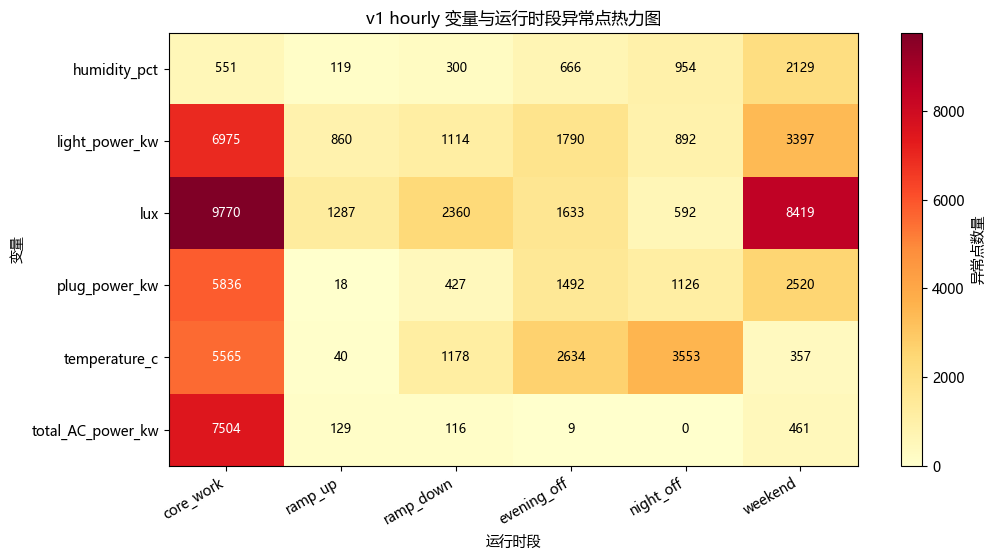

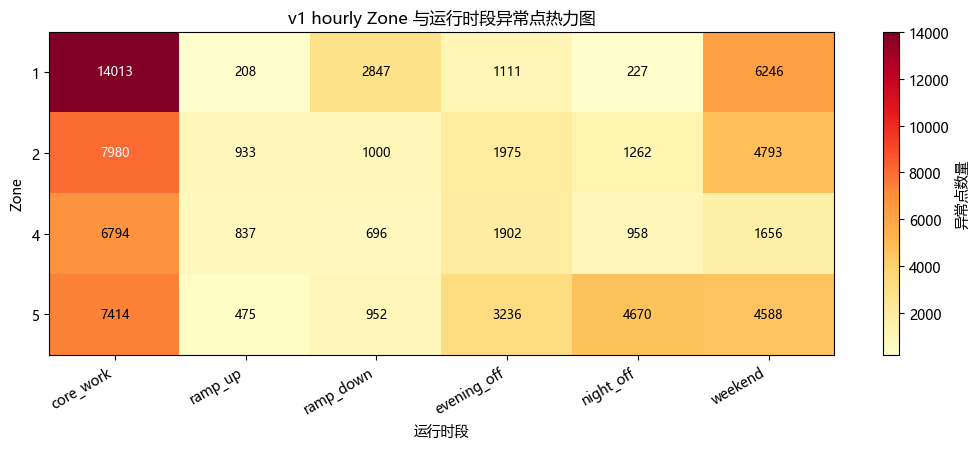

Running v2a_15min_slot: Finer 15-minute slot baseline to test intra-hour sensitivity.


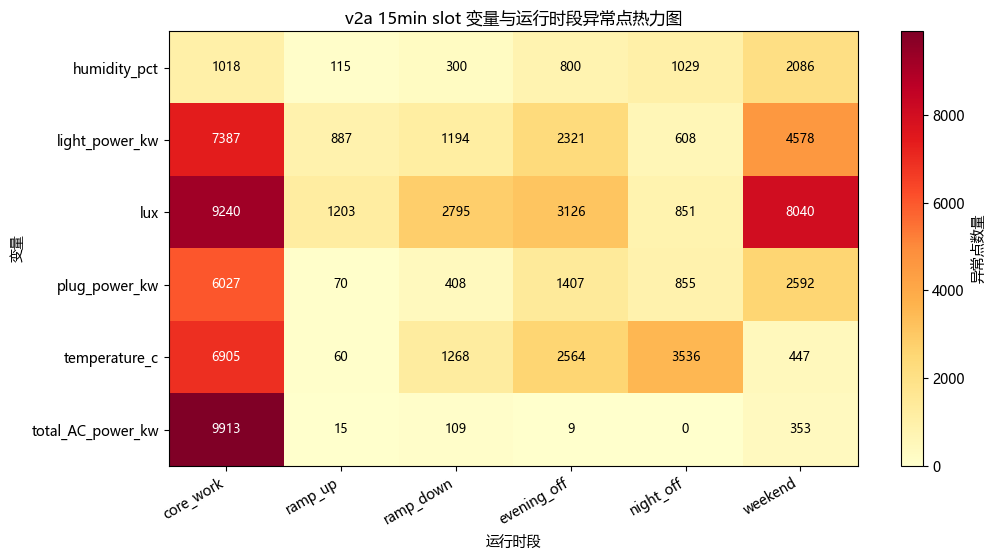

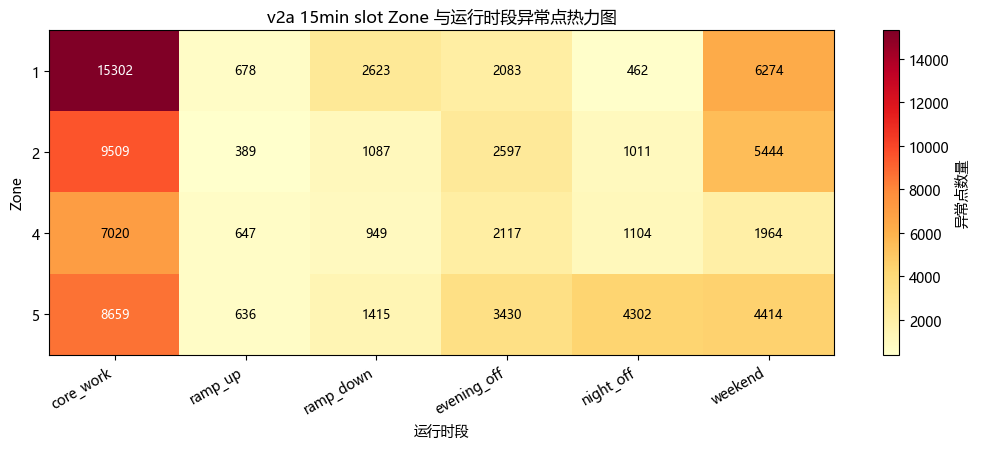

Running v2b_operation_aware: Hourly baseline with period-aware thresholds, variable-specific rules, dynamic persistence and severity ranking.


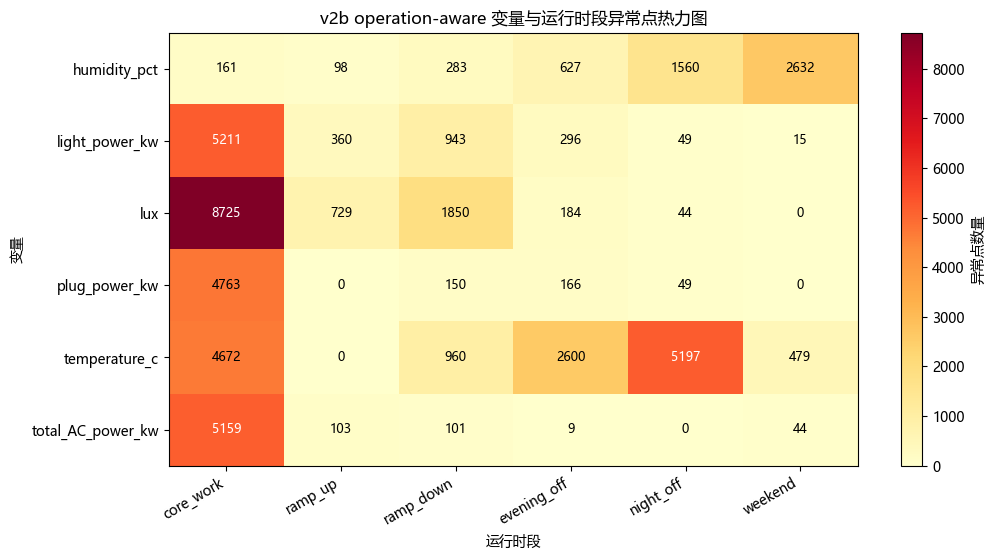

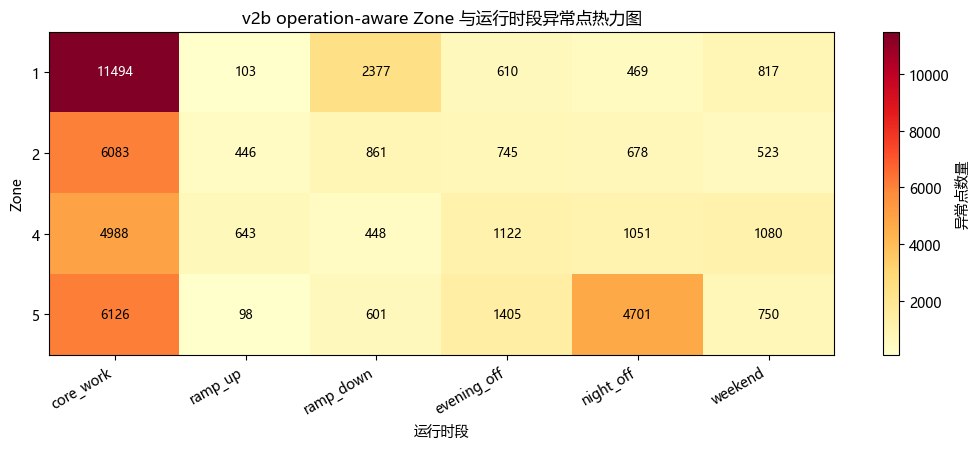

,method,baseline_grouping,rule_type,baseline_profile_rows,anomaly_points,anomaly_events
0,v1_hourly,zone + day_type + hour + variable,standard,1152,76773,940
1,v2a_15min_slot,zone + day_type + fifteen_minute_slot + variable,standard,4608,84116,1248
2,v2b_operation_aware,zone + day_type + hour + variable,operation_aware,1152,48219,281


In [5]:
baseline_results = {}

for method_id, config in METHOD_CONFIGS.items():
    safe_print(f"Running {method_id}: {config['description']}")
    baseline_results[method_id] = run_baseline_method(method_id, config)

validation_summary = pd.concat(
    [result["validation"] for result in baseline_results.values()],
    ignore_index=True,
)
validation_summary.to_csv(OPTIMIZED_TABLE_DIR / "05_validation_summary_all_methods.csv", index=False)

display(validation_summary[[
    "method", "baseline_grouping", "rule_type", "baseline_profile_rows",
    "anomaly_points", "anomaly_events"
]])


### 本步骤结果解释

三种 baseline 方法的运行结果如下：

- v1 hourly：基础小时级 baseline。
- v2a 15min slot：更细时间粒度 baseline，因此通常更敏感。
- v2b operation-aware：加入运行时段阈值、变量类型和动态持续时间，因此更偏向减少低优先级误报。

这一步的 validation summary 是后续所有比较图的基础。


## 6. Method Design Comparison

本步骤用表格总结三种方法的设计差异。


In [6]:
method_design = pd.DataFrame([
    {
        "method": "v1_hourly",
        "baseline_grouping": "zone + day_type + hour + variable",
        "threshold_rule": "统一 robust z >= 3.5；zero-aware rule 用于零值密集变量",
        "persistence_rule": "固定 15 分钟",
        "main_purpose": "建立稳定、可解释的第一版 statistical baseline",
    },
    {
        "method": "v2a_15min_slot",
        "baseline_grouping": "zone + day_type + 15min_slot + variable",
        "threshold_rule": "仍使用统一 robust z >= 3.5；zero-aware rule 与 v1 一致",
        "persistence_rule": "固定 15 分钟",
        "main_purpose": "测试更细时间粒度是否能捕捉小时内部变化",
    },
    {
        "method": "v2b_operation_aware",
        "baseline_grouping": "zone + day_type + hour + variable",
        "threshold_rule": "按运行时段调整阈值；非工作时间能源变量加强 zero-aware rule",
        "persistence_rule": "工作时间/环境变量 30 分钟，非工作时间能源异常 15 分钟",
        "main_purpose": "减少误报并突出更值得人工审查的异常事件",
    },
])
method_design.to_csv(OPTIMIZED_TABLE_DIR / "06_method_design_comparison.csv", index=False)
display(method_design)


,method,baseline_grouping,threshold_rule,persistence_rule,main_purpose
0,v1_hourly,zone + day_type + hour + variable,统一 robust z >= 3.5；zero-aware rule 用于零值密集变量,固定 15 分钟,建立稳定、可解释的第一版 statistical baseline
1,v2a_15min_slot,zone + day_type + 15min_slot + variable,仍使用统一 robust z >= 3.5；zero-aware rule 与 v1 一致,固定 15 分钟,测试更细时间粒度是否能捕捉小时内部变化
2,v2b_operation_aware,zone + day_type + hour + variable,按运行时段调整阈值；非工作时间能源变量加强 zero-aware rule,工作时间/环境变量 30 分钟，非工作时间能源异常 15 分钟,减少误报并突出更值得人工审查的异常事件


### 本步骤结果解释

这张表说明三个 baseline 版本不是重复实验，而是测试不同问题：

- v1 测试基础统计 baseline 是否能建立可解释的正常范围。
- v2a 测试时间粒度从小时变成 15 分钟后结果是否变化。
- v2b 测试按建筑运行逻辑调整阈值后是否能减少误报并提升解释性。


## 7. Overall Anomaly Count Comparison

本步骤比较三种方法检测到的异常点和异常事件数量。


Saved figure: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_baseline_methods_optimized\figures\01_overall_anomaly_points_and_events.png


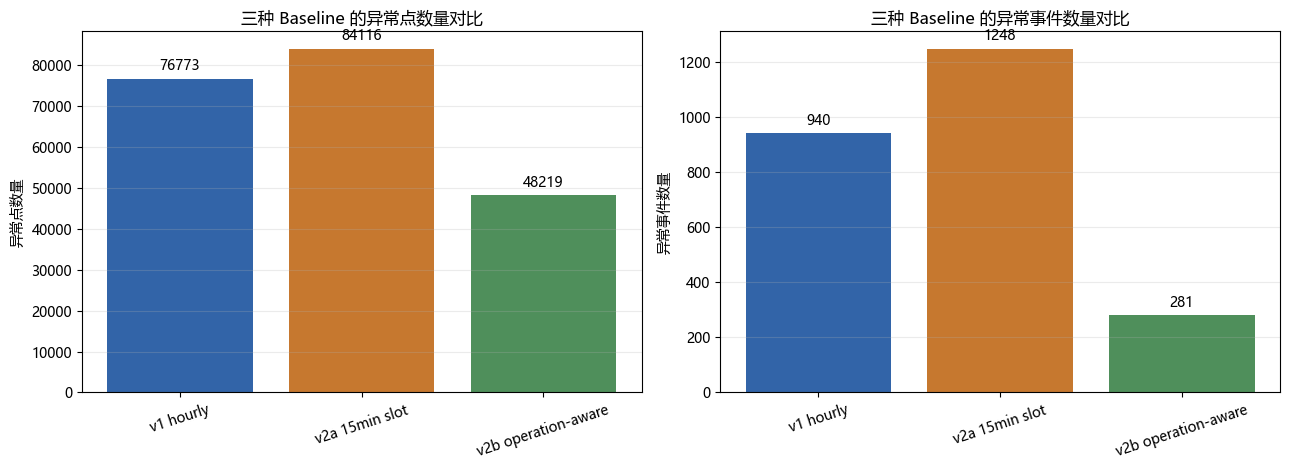

Saved figure: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_baseline_methods_optimized\figures\02_anomaly_points_only_comparison.png


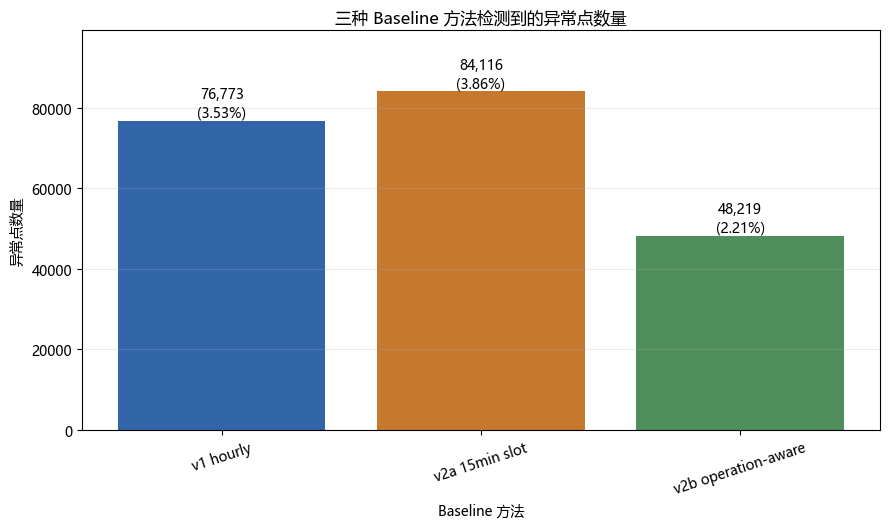

,method,method_label,anomaly_points,anomaly_events,baseline_profile_rows
0,v1_hourly,v1 hourly,76773,940,1152
1,v2a_15min_slot,v2a 15min slot,84116,1248,4608
2,v2b_operation_aware,v2b operation-aware,48219,281,1152


,method,anomaly_points,anomaly_point_pct
0,v1_hourly,76773,3.526252
1,v2a_15min_slot,84116,3.863523
2,v2b_operation_aware,48219,2.214742


In [7]:
def save_figure(file_name: str) -> None:
    path = OPTIMIZED_FIGURE_DIR / file_name
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches="tight")
    safe_print("Saved figure:", path)


overall = validation_summary[["method", "method_label", "anomaly_points", "anomaly_events", "baseline_profile_rows"]].copy()
overall.to_csv(OPTIMIZED_TABLE_DIR / "07_overall_count_comparison.csv", index=False)

colors = ["#3264a8", "#c6782f", "#4f8f5b"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

axes[0].bar(overall["method_label"], overall["anomaly_points"], color=colors)
axes[0].set_title("三种 Baseline 的异常点数量对比")
axes[0].set_ylabel("异常点数量")
axes[0].tick_params(axis="x", rotation=18)
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(overall["method_label"], overall["anomaly_events"], color=colors)
axes[1].set_title("三种 Baseline 的异常事件数量对比")
axes[1].set_ylabel("异常事件数量")
axes[1].tick_params(axis="x", rotation=18)
axes[1].grid(axis="y", alpha=0.25)

for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f", padding=3)

save_figure("01_overall_anomaly_points_and_events.png")
plt.show()

points_only = overall.merge(validation_summary[["method", "rows_input_long"]], on="method", how="left")
points_only["anomaly_point_pct"] = points_only["anomaly_points"] / points_only["rows_input_long"] * 100
points_only.to_csv(OPTIMIZED_TABLE_DIR / "08_anomaly_points_only_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5.4))
bars = ax.bar(points_only["method_label"], points_only["anomaly_points"], color=colors)
ax.set_title("三种 Baseline 方法检测到的异常点数量")
ax.set_xlabel("Baseline 方法")
ax.set_ylabel("异常点数量")
ax.tick_params(axis="x", rotation=18)
ax.grid(axis="y", alpha=0.25)
for bar, (_, row) in zip(bars, points_only.iterrows()):
    label = f"{int(row['anomaly_points']):,}\n({row['anomaly_point_pct']:.2f}%)"
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), label, ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, points_only["anomaly_points"].max() * 1.18)
save_figure("02_anomaly_points_only_comparison.png")
plt.show()

display(overall)
display(points_only[["method", "anomaly_points", "anomaly_point_pct"]])


### 本步骤结果解释

整体数量对比显示：

- v2a 的异常点和异常事件最多，因为 15 分钟时间槽 baseline 更敏感。
- v2b 的异常点和异常事件最少，因为它使用更符合运行逻辑的阈值和持续时间规则。
- v1 处于中间位置，适合作为 primary statistical baseline。


## 8. Variable, Zone and Operating Period Comparison

本步骤比较异常在变量、zone 和运行时段上的分布。


Saved figure: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_baseline_methods_optimized\figures\03_variable_level_comparison.png


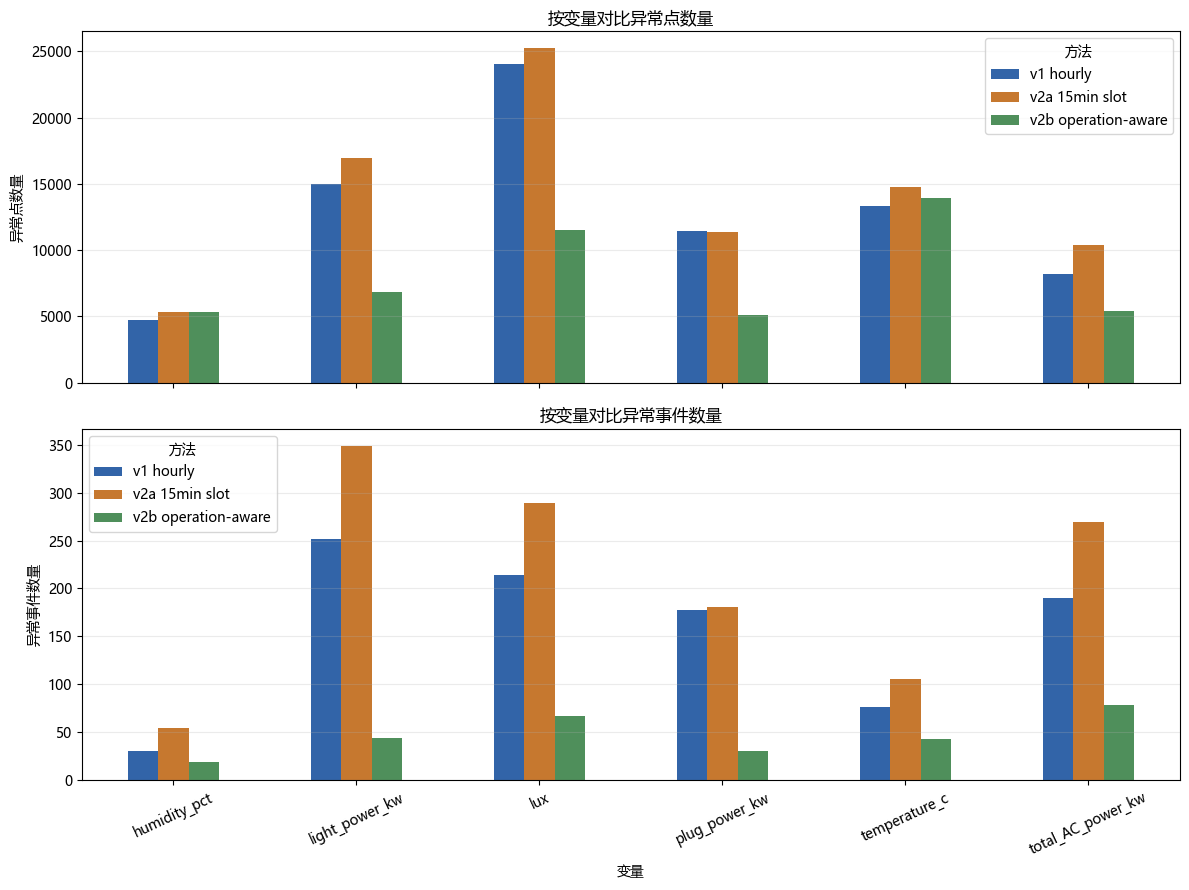

Saved figure: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_baseline_methods_optimized\figures\04_zone_and_period_comparison.png


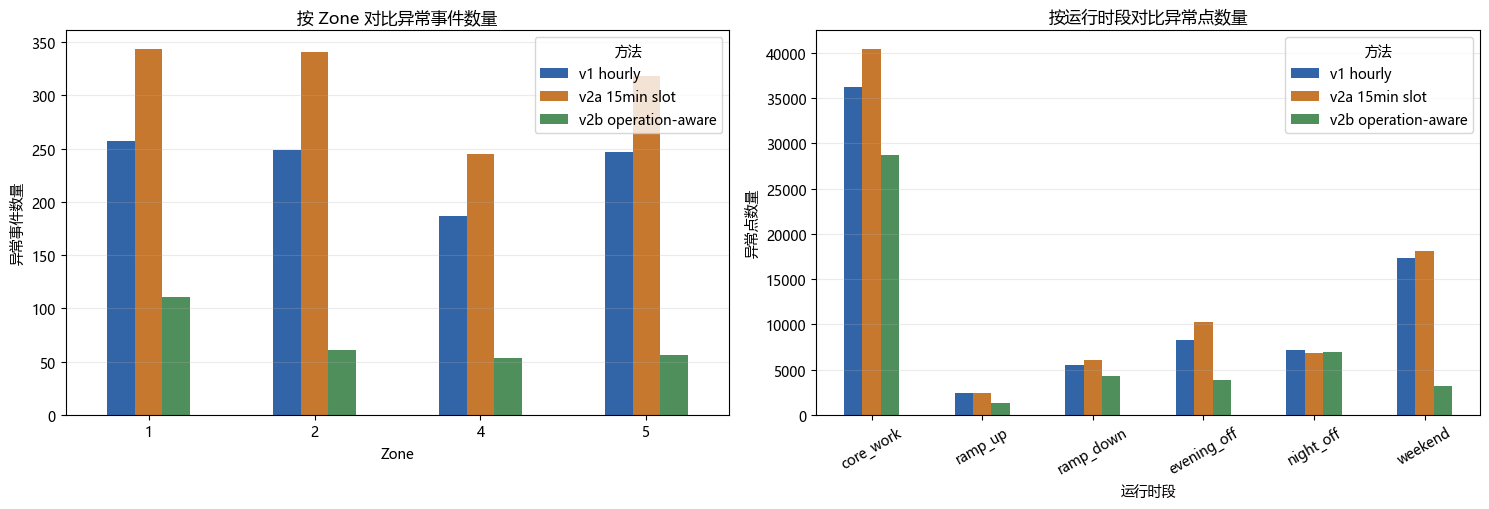

method_label,v1 hourly,v2a 15min slot,v2b operation-aware
variable,,,
humidity_pct,4719,5348,5361
light_power_kw,15028,16975,6874
lux,24061,25255,11532
plug_power_kw,11419,11359,5128
temperature_c,13327,14780,13908
total_AC_power_kw,8219,10399,5416


method_label,v1 hourly,v2a 15min slot,v2b operation-aware
variable,,,
humidity_pct,30,54,19
light_power_kw,252,349,44
lux,214,289,67
plug_power_kw,178,181,30
temperature_c,76,106,43
total_AC_power_kw,190,269,78


method_label,v1 hourly,v2a 15min slot,v2b operation-aware
zone,,,
1,257,344,111
2,249,341,61
4,187,245,53
5,247,318,56


method_label,v1 hourly,v2a 15min slot,v2b operation-aware
operating_period,,,
core_work,36201,40490,28691
ramp_up,2453,2350,1290
ramp_down,5495,6074,4287
evening_off,8224,10227,3882
night_off,7117,6879,6899
weekend,17283,18096,3170


In [8]:
method_order = [config["label"] for config in METHOD_CONFIGS.values()]

variable_point_summary = []
variable_event_summary = []
zone_event_summary = []
period_point_summary = []

for method_id, result in baseline_results.items():
    label = result["config"]["label"]

    variable_points = result["summaries"]["final_point_summary"].copy()
    variable_points["method"] = method_id
    variable_points["method_label"] = label
    variable_point_summary.append(variable_points)

    variable_events = result["summaries"]["summary_by_variable"].copy()
    variable_events["method"] = method_id
    variable_events["method_label"] = label
    variable_event_summary.append(variable_events)

    zone_events = result["summaries"]["summary_by_zone"].copy()
    zone_events["method"] = method_id
    zone_events["method_label"] = label
    zone_event_summary.append(zone_events)

    period_points = result["summaries"]["summary_by_period"].copy()
    period_points["method"] = method_id
    period_points["method_label"] = label
    period_point_summary.append(period_points)

variable_point_summary = pd.concat(variable_point_summary, ignore_index=True)
variable_event_summary = pd.concat(variable_event_summary, ignore_index=True)
zone_event_summary = pd.concat(zone_event_summary, ignore_index=True)
period_point_summary = pd.concat(period_point_summary, ignore_index=True)

variable_points_pivot = (
    variable_point_summary
    .pivot_table(index="variable", columns="method_label", values="anomaly_points", aggfunc="sum", fill_value=0)
    .reindex(columns=method_order)
)
variable_events_pivot = (
    variable_event_summary
    .pivot_table(index="variable", columns="method_label", values="events", aggfunc="sum", fill_value=0)
    .reindex(columns=method_order)
)
zone_events_pivot = (
    zone_event_summary
    .pivot_table(index="zone", columns="method_label", values="events", aggfunc="sum", fill_value=0)
    .reindex(columns=method_order)
)
period_points_pivot = (
    period_point_summary
    .pivot_table(index="operating_period", columns="method_label", values="anomaly_points", aggfunc="sum", fill_value=0)
    .reindex(index=OPERATING_PERIOD_ORDER, columns=method_order)
)

variable_points_pivot.to_csv(OPTIMIZED_TABLE_DIR / "09_variable_anomaly_points_pivot.csv")
variable_events_pivot.to_csv(OPTIMIZED_TABLE_DIR / "10_variable_anomaly_events_pivot.csv")
zone_events_pivot.to_csv(OPTIMIZED_TABLE_DIR / "11_zone_event_comparison.csv")
period_points_pivot.to_csv(OPTIMIZED_TABLE_DIR / "12_period_point_comparison.csv")

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
variable_points_pivot.plot(kind="bar", ax=axes[0], color=colors)
axes[0].set_title("按变量对比异常点数量")
axes[0].set_ylabel("异常点数量")
axes[0].grid(axis="y", alpha=0.25)
axes[0].legend(title="方法")

variable_events_pivot.plot(kind="bar", ax=axes[1], color=colors)
axes[1].set_title("按变量对比异常事件数量")
axes[1].set_ylabel("异常事件数量")
axes[1].set_xlabel("变量")
axes[1].tick_params(axis="x", rotation=25)
axes[1].grid(axis="y", alpha=0.25)
axes[1].legend(title="方法")
save_figure("03_variable_level_comparison.png")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
zone_events_pivot.plot(kind="bar", ax=axes[0], color=colors)
axes[0].set_title("按 Zone 对比异常事件数量")
axes[0].set_ylabel("异常事件数量")
axes[0].set_xlabel("Zone")
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", alpha=0.25)
axes[0].legend(title="方法")

period_points_pivot.plot(kind="bar", ax=axes[1], color=colors)
axes[1].set_title("按运行时段对比异常点数量")
axes[1].set_ylabel("异常点数量")
axes[1].set_xlabel("运行时段")
axes[1].tick_params(axis="x", rotation=30)
axes[1].grid(axis="y", alpha=0.25)
axes[1].legend(title="方法")
save_figure("04_zone_and_period_comparison.png")
plt.show()

display(variable_points_pivot)
display(variable_events_pivot)
display(zone_events_pivot)
display(period_points_pivot)


### 本步骤结果解释

按变量、zone 和运行时段比较可以帮助解释异常数量变化来自哪里。

v2a 对部分变量更敏感，说明更细时间槽会捕捉更多局部偏离；v2b 通过 operation-aware 规则减少短暂波动，更适合生成高优先级异常候选。


## 9. Overlap Between Methods

本步骤比较三个方法检测到的异常点是否重叠。重叠异常点通常更稳定，只被单一方法发现的点则用于 sensitivity analysis。


C:\Users\jh\AppData\Local\Temp\ipykernel_31716\1118140242.py:11: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  overlap[method_id] = overlap[method_id].fillna(False).astype(bool)
C:\Users\jh\AppData\Local\Temp\ipykernel_31716\1118140242.py:11: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  overlap[method_id] = overlap[method_id].fillna(False).astype(bool)
C:\Users\jh\AppData\Local\Temp\ipykernel_31716\1118140242.py:11: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.in

Saved figure: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_baseline_methods_optimized\figures\05_anomaly_point_overlap_comparison.png


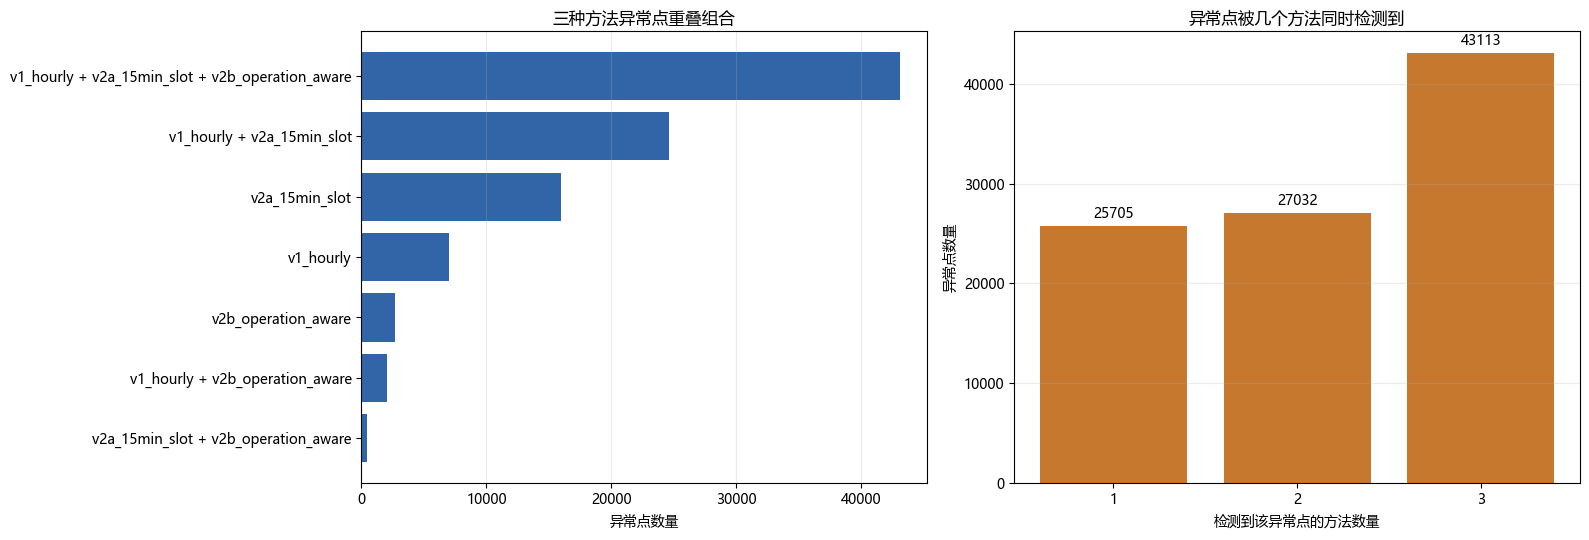

,combination,anomaly_points
2,v1_hourly + v2a_15min_slot + v2b_operation_aware,43113
1,v1_hourly + v2a_15min_slot,24610
4,v2a_15min_slot,15984
0,v1_hourly,7037
6,v2b_operation_aware,2684
3,v1_hourly + v2b_operation_aware,2013
5,v2a_15min_slot + v2b_operation_aware,409


,detected_by_count,anomaly_points
0,1,25705
1,2,27032
2,3,43113


In [9]:
overlap = None

for method_id, result in baseline_results.items():
    keys = result["anomaly_point_keys"]
    if overlap is None:
        overlap = keys
    else:
        overlap = overlap.merge(keys, on=["timestamp", "zone", "variable"], how="outer")

for method_id in METHOD_CONFIGS:
    overlap[method_id] = overlap[method_id].fillna(False).astype(bool)

overlap["detected_by_count"] = overlap[list(METHOD_CONFIGS.keys())].sum(axis=1)
overlap["combination"] = overlap[list(METHOD_CONFIGS.keys())].apply(
    lambda row: " + ".join([method for method, detected in row.items() if detected]),
    axis=1,
)

overlap_summary = (
    overlap.groupby("combination")
    .agg(anomaly_points=("timestamp", "size"))
    .reset_index()
    .sort_values("anomaly_points", ascending=False)
)
overlap_count_summary = (
    overlap.groupby("detected_by_count")
    .agg(anomaly_points=("timestamp", "size"))
    .reset_index()
    .sort_values("detected_by_count")
)

overlap_summary.to_csv(OPTIMIZED_TABLE_DIR / "13_anomaly_point_overlap_by_combination.csv", index=False)
overlap_count_summary.to_csv(OPTIMIZED_TABLE_DIR / "14_anomaly_point_overlap_by_method_count.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
axes[0].barh(overlap_summary["combination"], overlap_summary["anomaly_points"], color="#3264a8")
axes[0].set_title("三种方法异常点重叠组合")
axes[0].set_xlabel("异常点数量")
axes[0].invert_yaxis()
axes[0].grid(axis="x", alpha=0.25)

axes[1].bar(overlap_count_summary["detected_by_count"].astype(str), overlap_count_summary["anomaly_points"], color="#c6782f")
axes[1].set_title("异常点被几个方法同时检测到")
axes[1].set_xlabel("检测到该异常点的方法数量")
axes[1].set_ylabel("异常点数量")
axes[1].grid(axis="y", alpha=0.25)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.0f", padding=3)
save_figure("05_anomaly_point_overlap_comparison.png")
plt.show()

display(overlap_summary)
display(overlap_count_summary)


### 本步骤结果解释

重叠分析比单纯比较异常数量更有意义。

三个方法共同检测到的异常点可以作为高可信候选；只被 v2a 检测到的点说明 15 分钟时间槽更敏感；只被 v2b 检测到的点说明 operation-aware 规则能够捕捉一些非工作时间或高优先级模式。


## 10. Final Summary

本步骤输出最终比较表，总结三种 baseline 方法的主要结果和建议用途。


In [10]:
comparison_summary = overall.merge(
    method_design[["method", "threshold_rule", "persistence_rule", "main_purpose"]],
    on="method",
    how="left",
)
comparison_summary = comparison_summary[[
    "method", "method_label", "anomaly_points", "anomaly_events",
    "baseline_profile_rows", "threshold_rule", "persistence_rule", "main_purpose",
]]
comparison_summary.to_csv(OPTIMIZED_TABLE_DIR / "15_final_baseline_method_comparison_summary.csv", index=False)

safe_print("Optimized tables:", OPTIMIZED_TABLE_DIR)
safe_print("Optimized figures:", OPTIMIZED_FIGURE_DIR)
display(comparison_summary)


Optimized tables: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_baseline_methods_optimized\tables
Optimized figures: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_baseline_methods_optimized\figures


,method,method_label,anomaly_points,anomaly_events,baseline_profile_rows,threshold_rule,persistence_rule,main_purpose
0,v1_hourly,v1 hourly,76773,940,1152,统一 robust z >= 3.5；zero-aware rule 用于零值密集变量,固定 15 分钟,建立稳定、可解释的第一版 statistical baseline
1,v2a_15min_slot,v2a 15min slot,84116,1248,4608,仍使用统一 robust z >= 3.5；zero-aware rule 与 v1 一致,固定 15 分钟,测试更细时间粒度是否能捕捉小时内部变化
2,v2b_operation_aware,v2b operation-aware,48219,281,1152,按运行时段调整阈值；非工作时间能源变量加强 zero-aware rule,工作时间/环境变量 30 分钟，非工作时间能源异常 15 分钟,减少误报并突出更值得人工审查的异常事件


### 最终结论

v1 hourly baseline 是主要 statistical baseline，因为它稳定、可解释，适合作为报告中的主方法。

v2a 15-minute slot baseline 用于 sensitivity analysis。它检测到更多异常，说明更细时间粒度能捕捉更多小时内部变化，但也可能增加敏感性和误报。

v2b operation-aware baseline 更适合筛选高优先级异常。它减少了异常点和异常事件数量，并通过运行时段阈值、动态持续时间和 severity ranking 提高了结果的可解释性。

因此，最终报告中建议以 v1 为主线，使用 v2a 和 v2b 作为对比版本，说明 baseline 结果对时间粒度和运行规则的敏感性。
